# 13 - Presupuesto de Incertidumbre: Cuánto Confiar en un Registro

Los cuadernos 01 a 12 trataron la base de datos como si todos los registros
merecieran la misma confianza. Este cuaderno pregunta cuánto puede desviarse una
especie de la termoquímica de referencia. Desde la versión 0.5.0, `pyglenn`
incluye una envolvente de error por especie, expuesta por
`ThermochemicalCalculator.uncertainty`. La envolvente resume, en un conjunto de
números independiente de la temperatura, la diferencia entre los polinomios de
la NASA incluidos y las tablas NIST-JANAF: un sesgo y una banda de dos sigma para
Cp y H, y una banda absoluta de dos sigma para S.

El plan es breve. Primero vemos qué devuelve el método, después medimos cuánto
del catálogo está realmente validado, revisamos las especies que la envolvente
señala y terminamos propagando la banda a una entalpía de reacción.

In [1]:
import pandas as pd

from pyglenn import ThermochemicalCalculator

pd.set_option("display.float_format", lambda v: f"{v:,.3f}")


In [2]:
%matplotlib inline

import matplotlib.pyplot as plt
import numpy as np

plt.rcParams["figure.figsize"] = (8, 4.5)
plt.rcParams["axes.grid"] = True
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

## 1. Qué devuelve el método

`uncertainty(species_id, temperature)` devuelve un diccionario. La temperatura se
verifica contra el rango de la especie pero no cambia los números, porque la
envolvente es un único resumen para todo el intervalo.

| clave | significado |
|-----|---------|
| `cp_rel_bias` | desviación relativa media de Cp, en porcentaje |
| `cp_rel_2sigma` | banda relativa de dos sigma de Cp, en porcentaje |
| `h_rel_bias` | desviación relativa media de la entalpía estandarizada, en porcentaje |
| `h_rel_2sigma` | banda relativa de dos sigma de H, en porcentaje |
| `s_abs_2sigma` | banda de dos sigma de S, absoluta, en J/(mol K) |
| `n_ref_points` | número de puntos de referencia detrás de la envolvente |
| `source` | `nist-janaf` para especies validadas, `extrapolated` en otro caso |

In [3]:
with ThermochemicalCalculator() as calc:
    co2 = calc.get_available_species("CO2", exact_match=True)[0]
    envelope = calc.uncertainty(co2.id, 1000.0)

for key, value in envelope.items():
    print(f"{key:15s}: {value}")

species_id     : 316
species_name   : CO2
temperature    : 1000.0
cp_rel_bias    : 0.1874
cp_rel_2sigma  : 1.4138
h_rel_bias     : 0.0221
h_rel_2sigma   : 0.1668
s_abs_2sigma   : 0.0912
n_ref_points   : 16
source         : nist-janaf


## 2. Cuánto del catálogo está validado

La etiqueta de `source` importa más que los números. Una especie validada se
comparó punto por punto con datos tabulados de referencia. El resto lleva una
banda por defecto que proviene del estudio de validación, no de un ajuste a esa
especie concreta.

La figura siguiente pone lado a lado el reparto y la banda que lleva cada grupo.


In [4]:
with ThermochemicalCalculator() as calc:
    catalogue = calc.get_available_species("")
    rows = []
    for s in catalogue:
        low, high = calc.db.get_temperature_bounds(s.id)
        env = calc.uncertainty(s.id, 0.5 * (low + high))
        rows.append({
            "species": s.name,
            "source": "missing" if env is None else env["source"],
            "cp_bias": None if env is None else env["cp_rel_bias"],
            "cp_2sigma": None if env is None else env["cp_rel_2sigma"],
        })

bands = pd.DataFrame(rows)
bands["source"].value_counts()

source
extrapolated    2017
nist-janaf        18
Name: count, dtype: int64

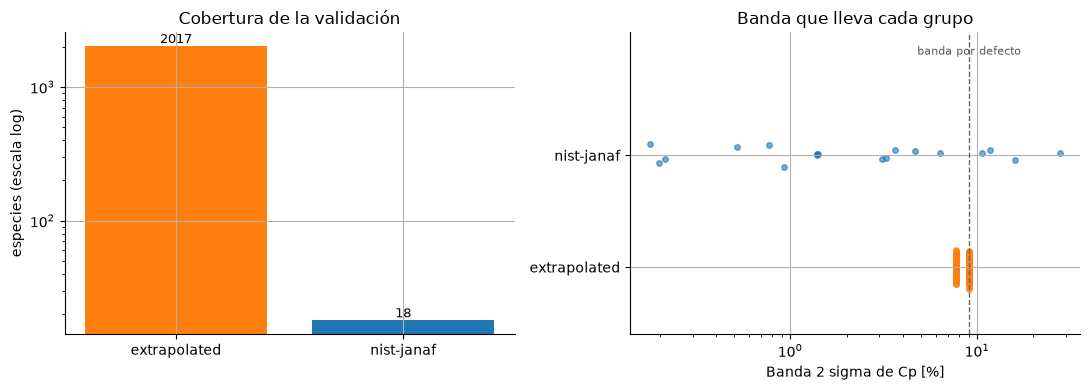

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

counts = bands["source"].value_counts()
tint = {"nist-janaf": "tab:blue", "extrapolated": "tab:orange", "missing": "0.6"}
ax1.bar(counts.index, counts.values, color=[tint[k] for k in counts.index])
ax1.set_yscale("log")
ax1.set_ylabel("especies (escala log)")
ax1.set_title("Cobertura de la validación")
for i, v in enumerate(counts.values):
    ax1.annotate(f"{v}", (i, v), ha="center", va="bottom", fontsize=9)

rng = np.random.default_rng(0)
groups = ["extrapolated", "nist-janaf"]
for row, label in enumerate(groups):
    band = bands.loc[bands["source"] == label, "cp_2sigma"].dropna()
    jitter = rng.normal(0.0, 0.05, len(band))
    ax2.scatter(band, row + jitter, s=16, alpha=0.6, color=tint[label])
default_band = bands.loc[bands["source"] == "extrapolated", "cp_2sigma"].median()
ax2.axvline(default_band, color="0.4", ls="--", lw=1)
ax2.annotate("banda por defecto", (default_band, 1.9), ha="center", fontsize=8, color="0.35")
ax2.set_xscale("log")
ax2.set_yticks(range(len(groups)))
ax2.set_yticklabels(groups)
ax2.set_ylim(-0.6, 2.1)
ax2.set_xlabel("Banda 2 sigma de Cp [%]")
ax2.set_title("Banda que lleva cada grupo")
plt.tight_layout()
plt.show()

El desequilibrio es grande. Solo dieciocho especies se validaron a mano y las otras
dos mil diecisiete heredan la envolvente por defecto. No es un defecto de la
biblioteca, es una afirmación sobre el costo de validar, y debería moderar
cualquier declaración de exactitud para una especie arbitraria.

## 3. Especies señaladas por la envolvente

La envolvente se justifica como herramienta de tamizaje. Entre las especies
validadas usadas en este cuaderno, el dióxido de carbono queda en 1.4 por ciento
en Cp, el oxígeno en 0.8 y el nitrógeno en 0.2; el agua llega a 3.1, y las
entradas extrapoladas llevan la banda por defecto de cerca de 9 por ciento.

In [6]:
names = ["CO2", "H2O", "O2", "N2", "CH4", "C2H5OH"]

rows = []
with ThermochemicalCalculator() as calc:
    for name in names:
        s = calc.get_available_species(name, exact_match=True)[0]
        env = calc.uncertainty(s.id, 1000.0)
        rows.append({
            "species": s.name,
            "source": env["source"],
            "Cp bias [%]": env["cp_rel_bias"],
            "Cp 2sigma [%]": env["cp_rel_2sigma"],
            "H 2sigma [%]": env["h_rel_2sigma"],
            "S 2sigma [J/mol/K]": env["s_abs_2sigma"],
        })

envelopes = pd.DataFrame(rows).set_index("species").round(2)
envelopes

,source,Cp bias [%],Cp 2sigma [%],H 2sigma [%],S 2sigma [J/mol/K]
species,,,,,
CO2,nist-janaf,0.190,1.410,0.170,0.090
H2O,nist-janaf,1.100,3.100,1.630,1.170
O2,nist-janaf,0.100,0.770,0.280,0.150
N2,nist-janaf,0.030,0.180,0.020,0.010
CH4,nist-janaf,8.820,27.610,13.550,17.290
C2H5OH,extrapolated,0.000,9.070,4.300,5.100


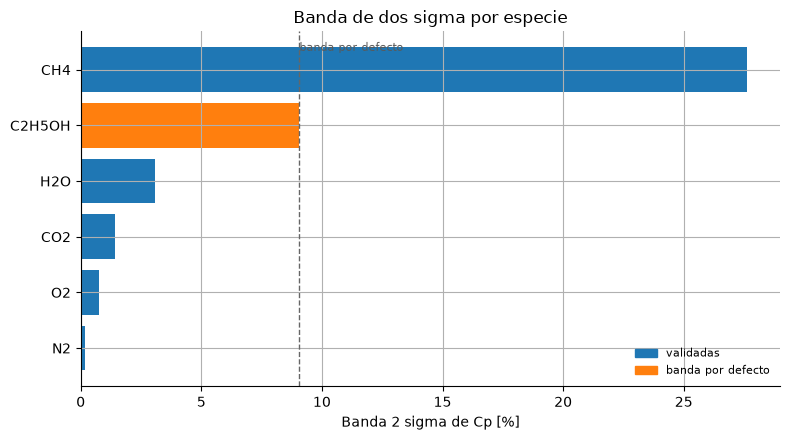

In [7]:
from matplotlib.patches import Patch

order = envelopes.sort_values("Cp 2sigma [%]")
default_band = envelopes.loc[envelopes["source"] == "extrapolated", "Cp 2sigma [%]"].iloc[0]
colour = ["tab:orange" if s == "extrapolated" else "tab:blue" for s in order["source"]]

fig, ax = plt.subplots()
ax.barh(order.index, order["Cp 2sigma [%]"], color=colour)
ax.axvline(default_band, color="0.4", ls="--", lw=1)
ax.annotate("banda por defecto", (default_band, len(order) - 0.5), va="top", fontsize=8, color="0.35")
ax.set_xlabel("Banda 2 sigma de Cp [%]")
ax.set_title("Banda de dos sigma por especie")
ax.legend(handles=[Patch(color="tab:blue", label="validadas"),
                   Patch(color="tab:orange", label="banda por defecto")],
          frameon=False, loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

El metano es la excepción, con 27.6 por ciento, un orden de magnitud por encima
de las demás. Una señal de ese tamaño no demuestra que el registro esté mal, pero sí
establece dónde mirar primero. La sección siguiente sigue esa pista.

## 4. Seguimiento de una especie señalada

La primera pregunta ante un registro señalado es si se sostienen las anclas
fundamentales. Tres valores bastan: la capacidad calorífica, la entropía y la
entalpía de formación a 298.15 K. Los valores de referencia del metano están
ampliamente tabulados y la comparación requiere un solo bucle.

In [8]:
anchors = {                      # NIST reference values for CH4(g)
    "Cp(298.15 K) [J/mol/K]": 35.69,
    "S(298.15 K) [J/mol/K]": 186.25,
    "dHf(298.15 K) [kJ/mol]": -74.87,
}

with ThermochemicalCalculator() as calc:
    ch4 = calc.get_available_species("CH4", exact_match=True)[0]
    props = calc.calculate_properties(ch4.id, 298.15)
    computed = {
        "Cp(298.15 K) [J/mol/K]": props.cp,
        "S(298.15 K) [J/mol/K]": props.s,
        "dHf(298.15 K) [kJ/mol]": props.h_relative / 1000.0,
    }

for label, reference in anchors.items():
    print(f"{label:24s} pyglenn {computed[label]:9.3f}   NIST {reference:9.3f}")

Cp(298.15 K) [J/mol/K]   pyglenn    35.691   NIST    35.690
S(298.15 K) [J/mol/K]    pyglenn   186.371   NIST   186.250
dHf(298.15 K) [kJ/mol]   pyglenn   -74.600   NIST   -74.870


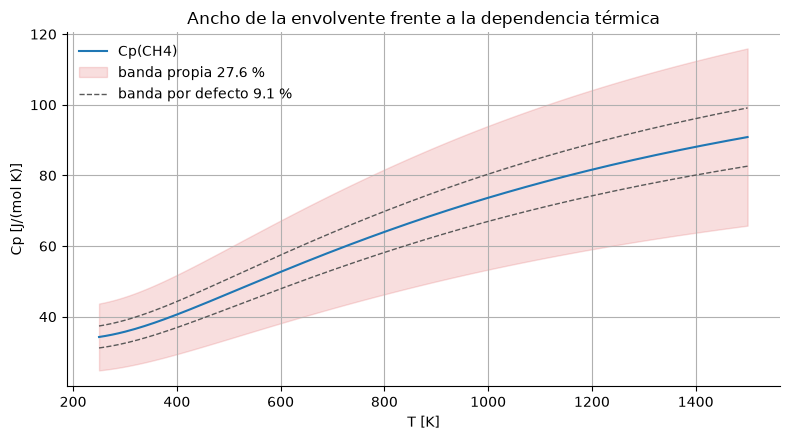

In [9]:
temps = np.linspace(250.0, 1500.0, 200)
with ThermochemicalCalculator() as calc:
    ch4_id = calc.get_available_species("CH4", exact_match=True)[0].id
    ethanol_id = calc.get_available_species("C2H5OH", exact_match=True)[0].id
    cp = np.array([calc.calculate_properties(ch4_id, T).cp for T in temps])
    own = calc.uncertainty(ch4_id, 1000.0)["cp_rel_2sigma"]
    default_band = calc.uncertainty(ethanol_id, 298.15)["cp_rel_2sigma"]

fig, ax = plt.subplots()
ax.plot(temps, cp, color="tab:blue", label="Cp(CH4)")
ax.fill_between(temps, cp * (1 - own / 100), cp * (1 + own / 100),
                color="tab:red", alpha=0.15, label="banda propia {:.1f} %".format(own))
for sign in (+1, -1):
    ax.plot(temps, cp * (1 + sign * default_band / 100), color="0.35", ls="--", lw=1,
            label="banda por defecto {:.1f} %".format(default_band) if sign > 0 else None)
ax.set_xlabel("T [K]")
ax.set_ylabel("Cp [J/(mol K)]")
ax.set_title("Ancho de la envolvente frente a la dependencia térmica")
ax.legend(frameon=False, loc="upper left")
plt.tight_layout()
plt.show()

Las tres anclas quedan a unas décimas de porcentaje de la referencia, así que el
registro es sólido cerca de la temperatura ambiente. La banda señalada se
concentra entonces a alta temperatura y en los desfases de entropía y entalpía,
no en la forma del polinomio que más usamos. La lección es de procedimiento: una
envolvente es un puntero, y el puntero debe seguirse con una verificación
independiente antes de declarar que algo está roto.

El gráfico de corredor hace visible la consecuencia: una banda medida una sola vez se convierte en una cuña que se ensancha con la temperatura.


## 5. Propagación de la banda a una entalpía de reacción

Para una combinación lineal, como una entalpía de reacción, las bandas se
combinan en cuadratura con los coeficientes estequiométricos como pesos. El
ejemplo siguiente toma la combustión completa del metano a 298.15 K y trata la
banda relativa de H como si se aplicara a la entalpía estandarizada de cada
especie.

In [10]:
reaction = {"CH4": -1.0, "O2": -2.0, "CO2": +1.0, "H2O": +2.0}

terms = []
with ThermochemicalCalculator() as calc:
    for name, nu in reaction.items():
        s = calc.get_available_species(name, exact_match=True)[0]
        h = calc.calculate_properties(s.id, 298.15).h_relative / 1000.0
        env = calc.uncertainty(s.id, 298.15)
        terms.append({
            "species": name,
            "nu": nu,
            "H [kJ/mol]": h,
            "2sigma [kJ/mol]": abs(h) * env["h_rel_2sigma"] / 100.0,
        })

table = pd.DataFrame(terms).set_index("species")
dH = float((table["nu"] * table["H [kJ/mol]"]).sum())
band = float(((table["nu"] * table["2sigma [kJ/mol]"]) ** 2).sum() ** 0.5)

print(table.round(2))
print(f"\nDelta H_rxn(298.15 K) = {dH:8.1f} kJ/mol")
print(f"combined 2sigma       = {band:8.1f} kJ/mol  ({100 * band / abs(dH):.1f} % of the enthalpy)")

            nu  H [kJ/mol]  2sigma [kJ/mol]
species                                    
CH4     -1.000     -74.600           10.110
O2      -2.000      -0.000            0.000
CO2      1.000    -393.510            0.660
H2O      2.000    -241.830            3.940

Delta H_rxn(298.15 K) =   -802.6 kJ/mol
combined 2sigma       =     12.8 kJ/mol  (1.6 % of the enthalpy)


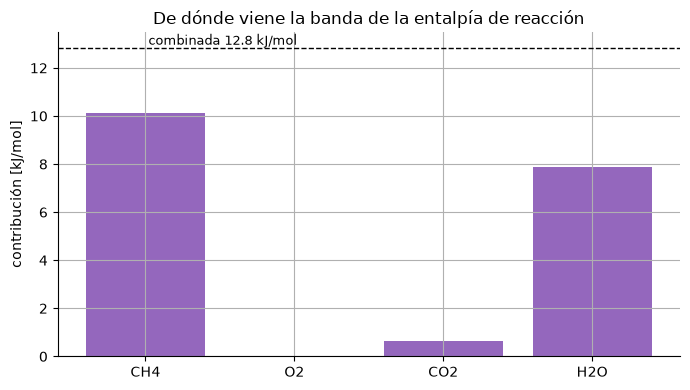

In [11]:
contrib = (table["nu"] * table["2sigma [kJ/mol]"]).abs()

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(contrib.index, contrib.values, color="tab:purple")
ax.axhline(band, color="k", ls="--", lw=1)
ax.annotate("combinada {:.1f} kJ/mol".format(band), (0.02, band), va="bottom", fontsize=9)
ax.set_ylabel("contribución [kJ/mol]")
ax.set_title("De dónde viene la banda de la entalpía de reacción")
plt.tight_layout()
plt.show()

La banda combinada de unos 13 kJ/mol corresponde al 1.6 por ciento de la
entalpía de reacción, y casi toda proviene del combustible. Esa asimetría es
típica: la especie con mayor entalpía de formación domina el presupuesto, de modo
que un combustible validado vale más que un producto validado.

## 6. Qué hacer con esto

Revisa la etiqueta de origen antes de confiar en una especie que sustente una
conclusión. Si el registro está validado, cita la banda junto al valor
calculado. Si es extrapolado, dilo. Si una banda parece anómala, compara la
especie con una tabla independiente antes de usarla en un modelo cuantitativo.
La envolvente reduce la búsqueda, no sustituye a la referencia.